# Visualization and feature selection: predicting developer sentiment toward AI

**Goal:** decide which columns (x) go into the model that predicts `AI_Sentiment_Score` (y), and show the evidence in charts.

**How to run:** open the project **folder** in VS Code, put this file in the project root (next to `README.md`), pick your Python kernel, then press **Run All**. Everything runs top to bottom in about a minute.

**What it uses:** only the *training* files (`03_X_train.csv`, `03_y_train.csv`, `03_train_readable.csv`), plus `02_manipulated.csv` for two descriptive charts. It never opens `03_X_test.csv` or `03_y_test.csv`. The test rows stay untouched until the final model is scored.

**What it saves:**
- `figures/v2_*.png`: the charts
- `feature_selection/selected_features.csv`: the final x list (for the modeling teammate)
- `feature_selection/dropped_features.csv`: every dropped column and why
- `feature_selection/selection_notes.md`: rules, numbers and chart notes, filled in automatically

**Plain-language terms used below**
- **Correlation (r):** a number from -1 to +1 for how closely two columns rise and fall together. 0 means no straight-line link. |r| means the size, ignoring the sign.
- **R squared (R2):** the share of the variation in y that a column (or group of columns) explains. r squared for a single column.
- **Cross-validation (5-fold):** split the training rows into 5 parts, train on 4, score on the 5th, repeat, and average. It gives an honest score without touching the test set.

The rules


In [19]:
THRESH_Y = 0.10       # keep a column if |r| with y is at least this (training rows only)
THRESH_PAIR = 0.80    # if two kept columns overlap at least this much, drop the one with the weaker link to y
THRESH_GROUP = 0.01   # country (12 columns) is judged as one group: keep it if together it explains at least this share (R2)
TIEBREAK = 0.01       # counts vs flags: use the flags only if their 5-fold R2 beats the counts' by at least this
CV_FOLDS = 5
RANDOM_STATE = 42
RUN_RF = True         # optional random forest cross-check (section 11); set False to skip

Set up and load the training data

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

pd.set_option("display.max_rows", None)       # show every row (VS Code otherwise hides the middle)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

P = Path("data/processed")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
OUT = Path("feature_selection"); OUT.mkdir(exist_ok=True)
TARGET = "AI_Sentiment_Score"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"   # validated categorical colours + a neutral grey


def save_fig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", FIG / name)


needed = ["02_manipulated.csv", "03_X_train.csv", "03_y_train.csv", "03_train_readable.csv", "03_feature_map.csv"]
absent = [f for f in needed if not (P / f).exists()]
assert not absent, f"Missing in {P.resolve()}: {absent}. Pull the latest files, or run 01_data_prep.py, and open the project FOLDER in VS Code."

X_train = pd.read_csv(P / "03_X_train.csv")
y_train = pd.read_csv(P / "03_y_train.csv").iloc[:, 0]
train_readable = pd.read_csv(P / "03_train_readable.csv")
manip = pd.read_csv(P / "02_manipulated.csv")
fmap = pd.read_csv(P / "03_feature_map.csv")
assert len(X_train) == len(y_train) == len(train_readable), "train files must have the same number of rows"
print("train rows:", len(X_train), "| model columns:", X_train.shape[1])

BEN = [c for c in X_train.columns if c.startswith("ben_")]
TOOL = [c for c in X_train.columns if c.startswith("tool_")]
COUNTRY = [c for c in X_train.columns if c.startswith("country_")]
COUNTS = ["AI_Tool_Count", "AI_Benefit_Breadth"]
NUMERIC = [c for c in X_train.columns if c not in BEN + TOOL + COUNTRY]
CORE = [c for c in NUMERIC if c not in COUNTS]          # numeric columns that are not counts of flags
assert all(c in X_train.columns for c in COUNTS)

GROUP_OF = {**{c: "numeric score or count" for c in NUMERIC}, **{c: "benefit flag" for c in BEN},
            **{c: "tool flag" for c in TOOL}, **{c: "country" for c in COUNTRY}}
GROUP_COLOR = {"numeric score or count": BLUE, "benefit flag": ORANGE, "tool flag": AQUA, "country": GREY}
display(pd.Series({g: sum(v == g for v in GROUP_OF.values()) for g in GROUP_COLOR}, name="model columns").to_frame())

train rows: 30028 | model columns: 37


,model columns
numeric score or count,6
benefit flag,7
tool flag,12
country,12


Descriptive charts

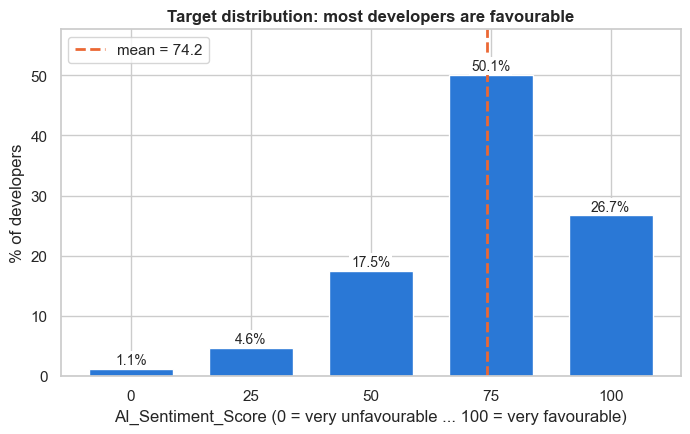

saved figures\v2_00_target_distribution.png
skewness: -0.82 (negative = tail to the left)


In [21]:
order = [0, 25, 50, 75, 100]
share = manip[TARGET].value_counts(normalize=True).reindex(order).fillna(0) * 100
mean_y = manip[TARGET].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([str(o) for o in order], share.values, color=BLUE, width=0.7)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10,
            zorder=5, bbox={"fc": "white", "ec": "none", "pad": 1.5})
ax.axvline(mean_y / 25, color=ORANGE, ls="--", lw=2, label=f"mean = {mean_y:.1f}")   # bar i sits at score i*25
ax.legend(loc="upper left", frameon=True)
ax.set_xlabel("AI_Sentiment_Score (0 = very unfavourable ... 100 = very favourable)")
ax.set_ylabel("% of developers")
ax.set_title("Target distribution: most developers are favourable", fontweight="bold")
ax.set_ylim(0, share.max() * 1.15)
save_fig(fig, "v2_00_target_distribution.png")
print("skewness:", round(manip[TARGET].skew(), 2), "(negative = tail to the left)")

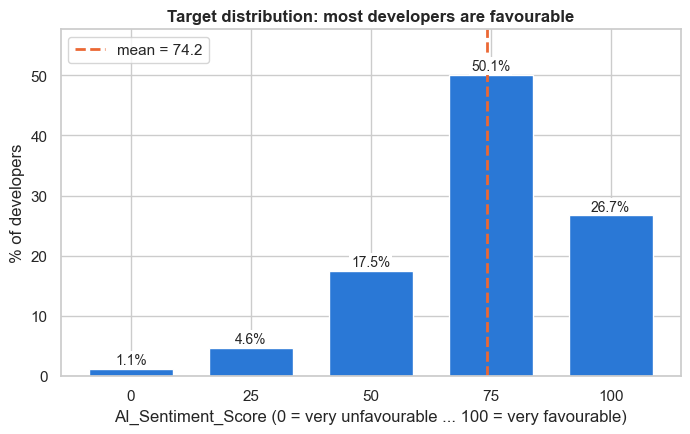

saved figures\v2_00_target_distribution.png
skewness: -0.82 (negative = tail to the left)


In [22]:
order = [0, 25, 50, 75, 100]
share = manip[TARGET].value_counts(normalize=True).reindex(order).fillna(0) * 100
mean_y = manip[TARGET].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([str(o) for o in order], share.values, color=BLUE, width=0.7)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10,
            zorder=5, bbox={"fc": "white", "ec": "none", "pad": 1.5})
ax.axvline(mean_y / 25, color=ORANGE, ls="--", lw=2, label=f"mean = {mean_y:.1f}")   # bar i sits at score i*25
ax.legend(loc="upper left", frameon=True)
ax.set_xlabel("AI_Sentiment_Score (0 = very unfavourable ... 100 = very favourable)")
ax.set_ylabel("% of developers")
ax.set_title("Target distribution: most developers are favourable", fontweight="bold")
ax.set_ylim(0, share.max() * 1.15)
save_fig(fig, "v2_00_target_distribution.png")
print("skewness:", round(manip[TARGET].skew(), 2), "(negative = tail to the left)")

 Understanding the columns

The audit file records what happened to each of the 44 raw columns. The rest of this notebook only chooses among the **candidates** it kept.

In [36]:
audit_path = P / "02_column_audit.csv"
if audit_path.exists():
    audit = pd.read_csv(audit_path)
    print("Raw columns by role:")
    display(audit.groupby("role").size().rename("columns").to_frame())
    print("Columns that were NOT kept as candidates, and why:")
    display(audit.loc[~audit["role"].isin(["candidate", "target"]), ["raw_column", "role", "reason"]].reset_index(drop=True))
else:
    print("02_column_audit.csv not found - skipping this table.")

Raw columns by role:


,columns
role,
candidate,26
constant,3
duplicate,4
id,1
leakage,1
metadata,4
no_codebook,4
target,1


Columns that were NOT kept as candidates, and why:


,raw_column,role,reason
0,respondent_id,id,"Row label only; kept in the readable files so rows can be traced, never a predictor."
1,developer_type,no_codebook,"Numeric codes; the Kaggle file ships no code book, so we cannot say what the codes mean. Removed rather th..."
2,age_range,no_codebook,"Numeric codes; the Kaggle file ships no code book, so we cannot say what the codes mean. Removed rather th..."
3,education_level,no_codebook,"Numeric codes; the Kaggle file ships no code book, so we cannot say what the codes mean. Removed rather th..."
4,years_professional_coding,duplicate,Identical to years_professional_coding_num in every row.
5,organization_size,no_codebook,"Numeric codes; the Kaggle file ships no code book, so we cannot say what the codes mean. Removed rather th..."
6,ai_tool_stance,constant,"We filtered on it (=3), so it has a single value now."
7,ai_overall_sentiment,leakage,The raw survey answer AI_Sentiment_Score is built from (every raw code maps to one score). Using it would ...
8,ai_accuracy_trust,duplicate,Raw alphabetical codes of AI_Trust_Score (one-to-one). We keep the correctly ordered AI_Trust_Score.
9,ai_job_threat_concern,duplicate,Raw alphabetical codes of AI_Job_Integration_Comfort (one-to-one). We keep the ordered version.


 Rank every column by correlation with y (training rows only)
 For each of the 37 columns this works out r, its straight-line link to sentiment. A **positive** r means higher values go with more favourable sentiment, a **negative** r the opposite. For a yes/no flag it compares people who ticked it with people who did not.

The dashed lines mark your cut-off (+/- `THRESH_Y`). A bar that reaches past a dashed line passes.

,r,group,passes
AI_Trust_Score,0.460,numeric score or count,True
ai_complex_task_concern,0.390,numeric score or count,True
AI_Benefit_Breadth,0.367,numeric score or count,True
ben_increase_productivity,0.296,benefit flag,True
AI_Tool_Count,0.291,numeric score or count,True
ben_greater_efficiency,0.249,benefit flag,True
tool_writing_code,0.227,tool flag,True
ben_improve_accuracy_in_coding,0.175,benefit flag,True
ben_speed_up_learning,0.171,benefit flag,True
tool_debugging_and_getting_help,0.169,tool flag,True


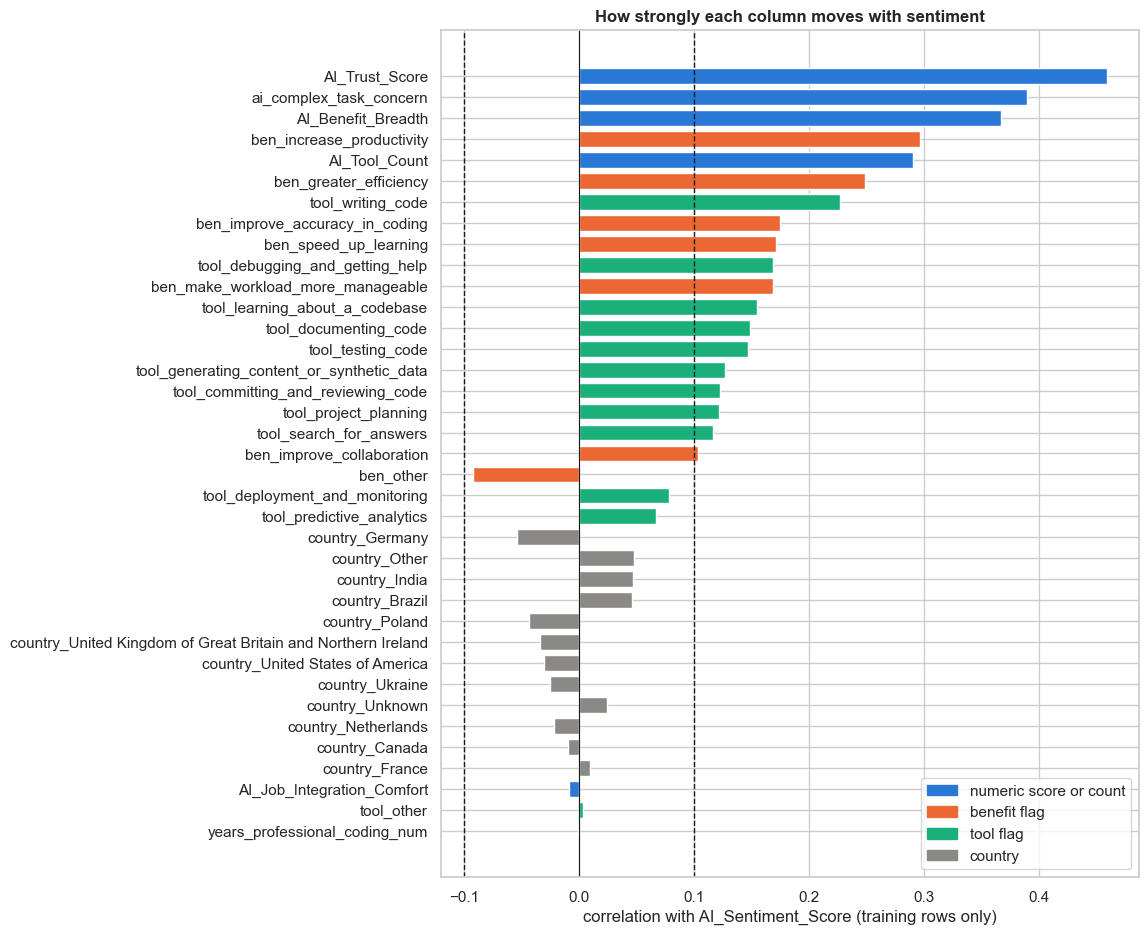

saved figures\v2_02_correlation_with_target.png
19 of 37 columns pass |r| >= 0.1


In [37]:
r = X_train.corrwith(y_train)
rank = r.abs().sort_values(ascending=False)
ranking = pd.DataFrame({"r": r.loc[rank.index].round(3),
                        "group": [GROUP_OF[c] for c in rank.index],
                        "passes": (rank >= THRESH_Y).values})
display(ranking)

order_plot = list(rank.index[::-1])                       # strongest ends up at the top
fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(order_plot, r.loc[order_plot], color=[GROUP_COLOR[GROUP_OF[c]] for c in order_plot], height=0.75)
ax.axvline(THRESH_Y, ls="--", color="k", lw=1)
ax.axvline(-THRESH_Y, ls="--", color="k", lw=1)
ax.axvline(0, color="k", lw=0.8)
ax.legend(handles=[Patch(color=v, label=k) for k, v in GROUP_COLOR.items()], loc="lower right", frameon=True)
ax.set_xlabel("correlation with AI_Sentiment_Score (training rows only)")
ax.set_title("How strongly each column moves with sentiment", fontweight="bold")
save_fig(fig, "v2_02_correlation_with_target.png")
print(f"{int(ranking['passes'].sum())} of {len(ranking)} columns pass |r| >= {THRESH_Y}")

Country as a group

The 12 country columns add up to 1 (each person is in exactly one). Judging them one by one is unfair, so we ask how much of y they explain **together** (R2) and compare it with the strongest single columns. A single column's R2 is r squared.

In [38]:
country_model = LinearRegression().fit(X_train[COUNTRY], y_train)
country_r2 = country_model.score(X_train[COUNTRY], y_train)
country_passes = country_r2 >= THRESH_GROUP
print(f"country as a group: R2 = {country_r2:.3f} (rule: at least {THRESH_GROUP}) -> "
      f"{'KEEP all country columns together' if country_passes else 'DROP all country columns'}")
print("For comparison, the strongest single columns (r squared):")
display(((r ** 2).sort_values(ascending=False).head(6).round(3)).to_frame("r squared"))

country as a group: R2 = 0.014 (rule: at least 0.01) -> KEEP all country columns together
For comparison, the strongest single columns (r squared):


,r squared
AI_Trust_Score,0.211
ai_complex_task_concern,0.152
AI_Benefit_Breadth,0.135
ben_increase_productivity,0.088
AI_Tool_Count,0.084
ben_greater_efficiency,0.062


Heatmaps: do any x columns overlap?

Two x columns that say nearly the same thing (|r| of 0.80 or more) make a model's coefficients hard to read, so the rule drops the weaker of any such pair. One 37-column heatmap is unreadable, so there is one per block. The numeric heatmap also includes y, which shows the same links as section 5 in grid form.

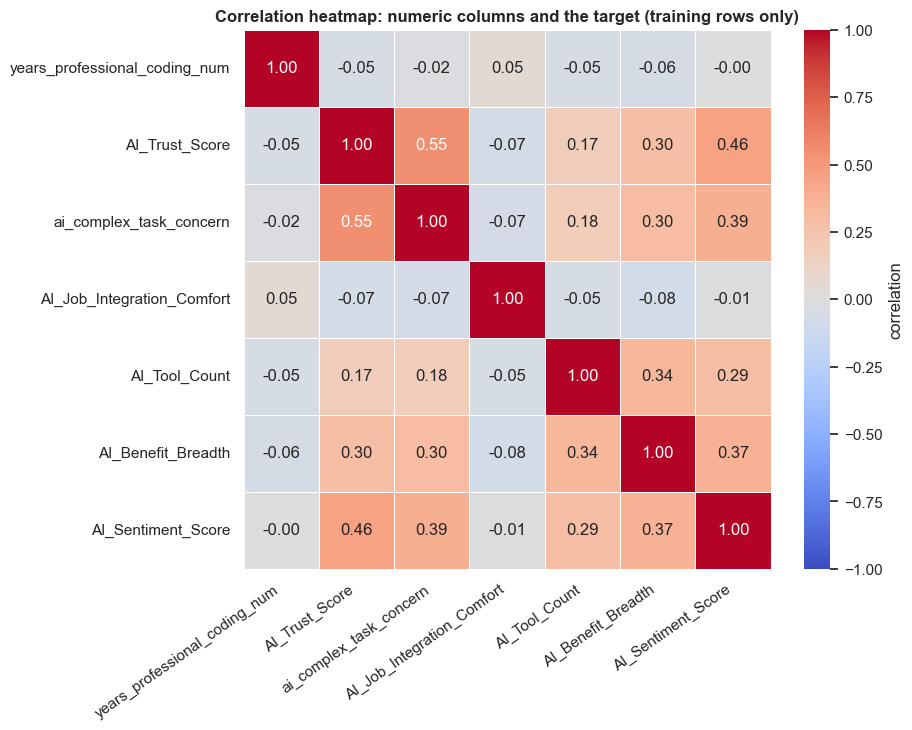

saved figures\v2_03_heatmap_numeric_with_target.png


In [39]:
num_view = X_train[NUMERIC].copy()
num_view[TARGET] = y_train.values
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(num_view.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "correlation"}, ax=ax)
ax.set_title("Correlation heatmap: numeric columns and the target (training rows only)", fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save_fig(fig, "v2_03_heatmap_numeric_with_target.png")

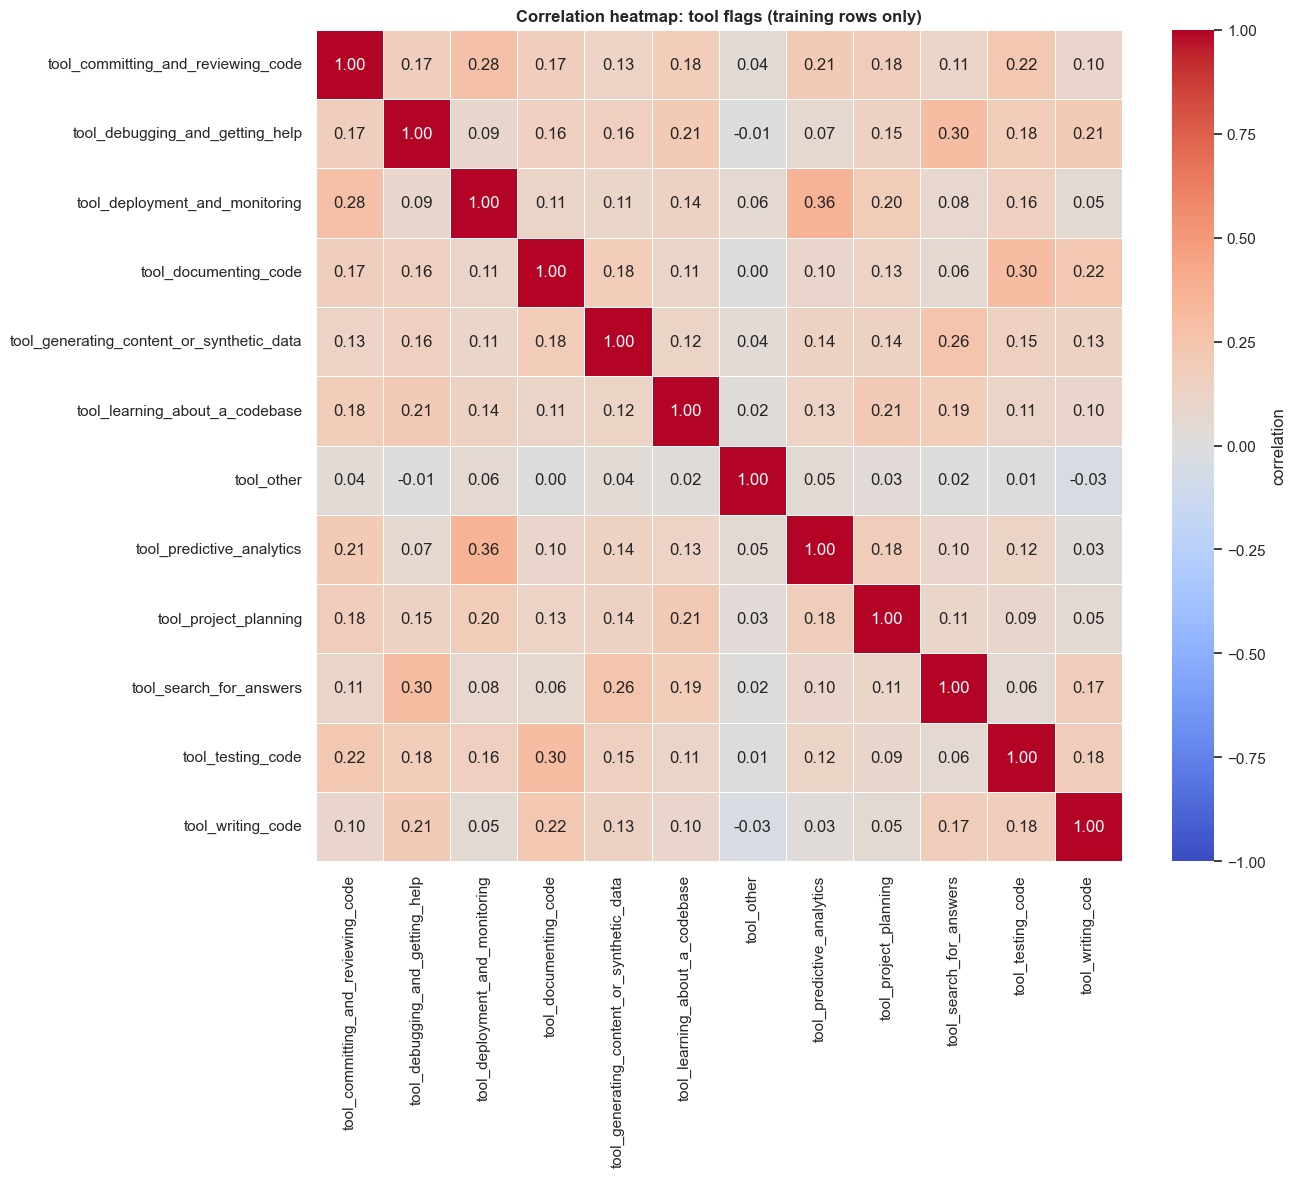

saved figures\v2_04_heatmap_tool_flags.png


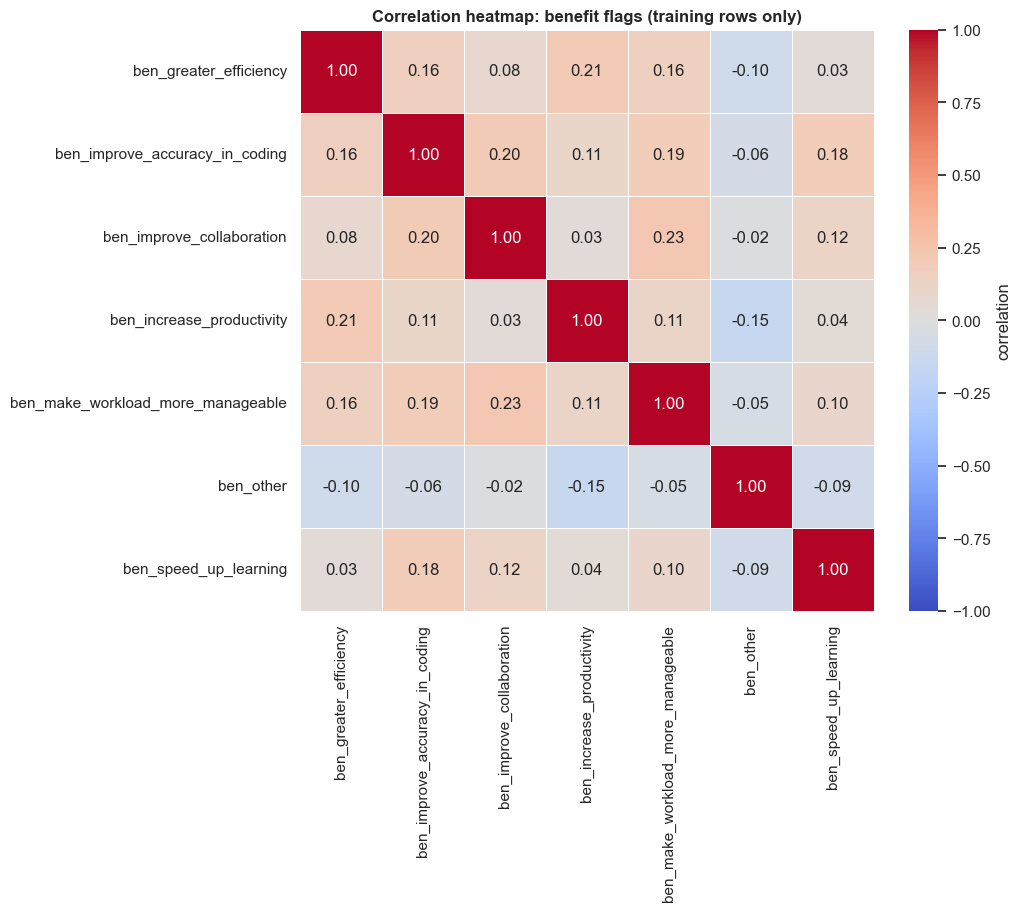

saved figures\v2_05_heatmap_benefit_flags.png


In [40]:
def block_heatmap(cols, title, fname):
    n = len(cols)
    fig, ax = plt.subplots(figsize=(0.75 * n + 4, 0.65 * n + 3))
    sns.heatmap(X_train[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                linewidths=0.5, cbar_kws={"label": "correlation"}, ax=ax)
    ax.set_title(title, fontweight="bold")
    save_fig(fig, fname)


block_heatmap(TOOL, "Correlation heatmap: tool flags (training rows only)", "v2_04_heatmap_tool_flags.png")
block_heatmap(BEN, "Correlation heatmap: benefit flags (training rows only)", "v2_05_heatmap_benefit_flags.png")

In [41]:
corr_all = X_train.corr()
upper = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1))
pairs = upper.stack().reset_index()
pairs.columns = ["a", "b", "r"]
pairs["abs_r"] = pairs["r"].abs()
overlap_pairs = pairs[pairs["abs_r"] >= THRESH_PAIR].sort_values("abs_r", ascending=False)
print(f"Pairs with |r| >= {THRESH_PAIR}: {len(overlap_pairs)}")
print("The 8 strongest overlaps among all 37 columns, for the record:")
display(pairs.sort_values("abs_r", ascending=False).head(8)[["a", "b", "r"]].round(2).reset_index(drop=True))

Pairs with |r| >= 0.8: 0
The 8 strongest overlaps among all 37 columns, for the record:


,a,b,r
0,AI_Benefit_Breadth,ben_improve_accuracy_in_coding,0.59
1,AI_Tool_Count,tool_debugging_and_getting_help,0.57
2,AI_Benefit_Breadth,ben_make_workload_more_manageable,0.56
3,AI_Benefit_Breadth,ben_greater_efficiency,0.56
4,AI_Trust_Score,ai_complex_task_concern,0.55
5,AI_Tool_Count,tool_documenting_code,0.52
6,AI_Tool_Count,tool_generating_content_or_synthetic_data,0.51
7,AI_Tool_Count,tool_search_for_answers,0.51


Counts or flags?

`AI_Tool_Count` is the exact sum of the `tool_*` flags, and `AI_Benefit_Breadth` the exact sum of the `ben_*` flags. They carry the same information, so keep **one side** only.

Two views:
1. Does the count's link to y beat every single flag's? (A sum naturally beats any one part, so this favours the counts.)
2. Does a model with the passing flags predict better than one with the counts, measured by 5-fold cross-validation on the training rows? If the flags win by at least `TIEBREAK`, use the flags.

In [42]:
rows = []
for count_col, flags in [("AI_Tool_Count", TOOL), ("AI_Benefit_Breadth", BEN)]:
    best = r[flags].abs().idxmax()
    rows.append({"count": count_col, "count |r|": abs(r[count_col]), "best single flag": best,
                 "best flag |r|": abs(r[best]), "count beats every flag": abs(r[count_col]) > abs(r[best]),
                 "highest r with its own flags": X_train[flags].corrwith(X_train[count_col]).max()})
display(pd.DataFrame(rows).round(3))

,count,count |r|,best single flag,best flag |r|,count beats every flag,highest r with its own flags
0,AI_Tool_Count,0.291,tool_writing_code,0.227,True,0.565
1,AI_Benefit_Breadth,0.367,ben_increase_productivity,0.296,True,0.595


In [43]:
core_pass = [c for c in CORE if abs(r[c]) >= THRESH_Y]
counts_pass = [c for c in COUNTS if abs(r[c]) >= THRESH_Y]
flags_pass = [c for c in BEN + TOOL if abs(r[c]) >= THRESH_Y]
set_counts = core_pass + counts_pass
set_flags = core_pass + flags_pass


def cv_r2(cols):
    return cross_val_score(LinearRegression(), X_train[cols], y_train, cv=CV_FOLDS, scoring="r2").mean()


cv_counts, cv_flags = cv_r2(set_counts), cv_r2(set_flags)
use_flags = (cv_flags - cv_counts) >= TIEBREAK
display(pd.DataFrame({"set": ["counts", "flags"], "columns": [len(set_counts), len(set_flags)],
                      f"{CV_FOLDS}-fold R2 on train": [round(cv_counts, 3), round(cv_flags, 3)]}))
print(f"flags beat counts by {cv_flags - cv_counts:.3f}; tie-break is {TIEBREAK} -> use the "
      f"{'FLAGS' if use_flags else 'COUNTS'}")

,set,columns,5-fold R2 on train
0,counts,4,0.305
1,flags,17,0.334


flags beat counts by 0.029; tie-break is 0.01 -> use the FLAGS


Sanity check for the two numeric columns the rule drops

Correlation only sees *straight-line* links. This checks that average sentiment really is flat across the levels of job comfort and years of coding. If the averages are within a few points of each other, dropping them is safe.

In [44]:
tmp = pd.DataFrame({"job_comfort": train_readable["AI_Job_Integration_Comfort"].values,
                    "years": train_readable["years_professional_coding_num"].values,
                    "sentiment": y_train.values})
print("Average sentiment by job-comfort level (10 = fears AI threatens job, 50 = unsure, 100 = does not):")
display(tmp.groupby("job_comfort")["sentiment"].agg(["mean", "count"]).round(1))
print("Average sentiment by years of professional coding:")
display(tmp.groupby(pd.cut(tmp["years"], [-1, 1, 3, 5, 8, 12, 20, 60]), observed=True)["sentiment"]
        .agg(["mean", "count"]).round(1))

Average sentiment by job-comfort level (10 = fears AI threatens job, 50 = unsure, 100 = does not):


,mean,count
job_comfort,,
10.0,75.0,3526
50.0,73.9,5692
100.0,74.1,19830


Average sentiment by years of professional coding:


,mean,count
years,,
"(-1, 1]",74.4,2951
"(1, 3]",73.8,4534
"(3, 5]",74.8,3509
"(5, 8]",73.6,3939
"(8, 12]",74.3,3602
"(12, 20]",73.9,3737
"(20, 60]",74.0,2598


Apply the rules: the final x list

The rules, in order:
1. Keep a column if |r| with y is at least `THRESH_Y`.
2. Counts or flags: keep only the winning side (section 8).
3. Country: keep all 12 columns together if the group passes (section 6), otherwise none.
4. If two kept columns overlap at `THRESH_PAIR` or more, drop the one with the weaker link to y.

In [ ]:
selected = list(core_pass) + (flags_pass if use_flags else counts_pass) + (COUNTRY if country_passes else [])

overlap_dropped = {}
for _, row in overlap_pairs.iterrows():
    a, b = row["a"], row["b"]
    if a in selected and b in selected:
        loser = a if abs(r[a]) < abs(r[b]) else b
        winner = b if loser == a else a
        selected.remove(loser)
        overlap_dropped[loser] = f"overlaps {winner} (|r| between them = {row['abs_r']:.2f})"

reason = {}
for c in X_train.columns:
    if c in selected:
        continue
    if c in overlap_dropped:
        reason[c] = overlap_dropped[c]
    elif c in COUNTS and use_flags and abs(r[c]) >= THRESH_Y:
        reason[c] = (f"count replaced by its own flags (flags set {cv_flags:.3f} vs counts set {cv_counts:.3f} "
                     f"in {CV_FOLDS}-fold R2, gap at least {TIEBREAK})")
    elif c in BEN + TOOL and not use_flags and abs(r[c]) >= THRESH_Y:
        reason[c] = (f"passes the cut (|r| = {abs(r[c]):.3f}) but is represented by its count "
                     f"(counts set {cv_counts:.3f} vs flags set {cv_flags:.3f}, gap below {TIEBREAK})")
    elif c in COUNTRY and not country_passes:
        reason[c] = f"country as a group explains {country_r2:.3f}, below {THRESH_GROUP}"
    else:
        reason[c] = f"|r| with y = {abs(r[c]):.3f}, below the {THRESH_Y} cut"

assert not (set(COUNTS) & set(selected) and set(BEN + TOOL) & set(selected)), "a count and its own flags are both selected"
assert set(selected) | set(reason) == set(X_train.columns) and not (set(selected) & set(reason))

print(f"{len(selected)} columns selected, {len(reason)} dropped\n")
for g in GROUP_COLOR:
    cols = [c for c in selected if GROUP_OF[c] == g]
    print(f"{g} ({len(cols)}):", ", ".join(cols) if g != "country" else f"{len(cols)} country columns")
print("\nDropped columns and why:")
display(pd.DataFrame({"dropped": list(reason), "why": list(reason.values())}))

In [23]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

P = Path("data/processed")
X_train = pd.read_csv(P / "03_X_train.csv")
y_train = pd.read_csv(P / "03_y_train.csv").iloc[:, 0]
train_readable = pd.read_csv(P / "03_train_readable.csv")
fmap = pd.read_csv(P / "03_feature_map.csv")

print(X_train.shape, y_train.shape, train_readable.shape)
assert len(X_train) == len(y_train) == len(train_readable)
fmap.head(40)

(30028, 37) (30028,) (30028, 29)


,feature,source_column,kind
0,years_professional_coding_num,years_professional_coding_num,numeric (scaled)
1,AI_Trust_Score,AI_Trust_Score,numeric (scaled)
2,ai_complex_task_concern,ai_complex_task_concern,numeric (scaled)
3,AI_Job_Integration_Comfort,AI_Job_Integration_Comfort,numeric (scaled)
4,AI_Tool_Count,AI_Tool_Count,numeric (scaled)
5,AI_Benefit_Breadth,AI_Benefit_Breadth,numeric (scaled)
6,ben_greater_efficiency,ben_greater_efficiency,0/1 flag
7,ben_improve_accuracy_in_coding,ben_improve_accuracy_in_coding,0/1 flag
8,ben_improve_collaboration,ben_improve_collaboration,0/1 flag
9,ben_increase_productivity,ben_increase_productivity,0/1 flag


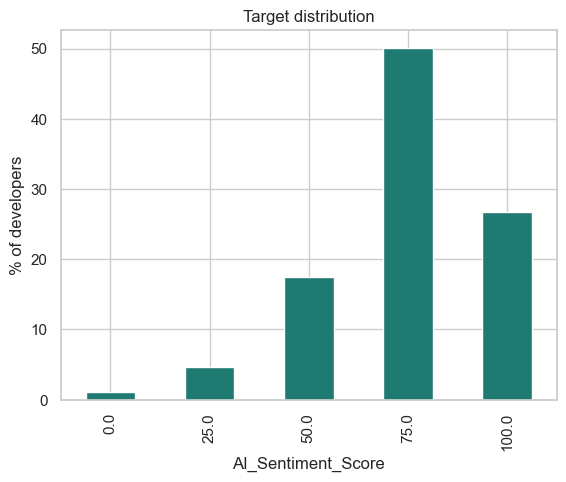

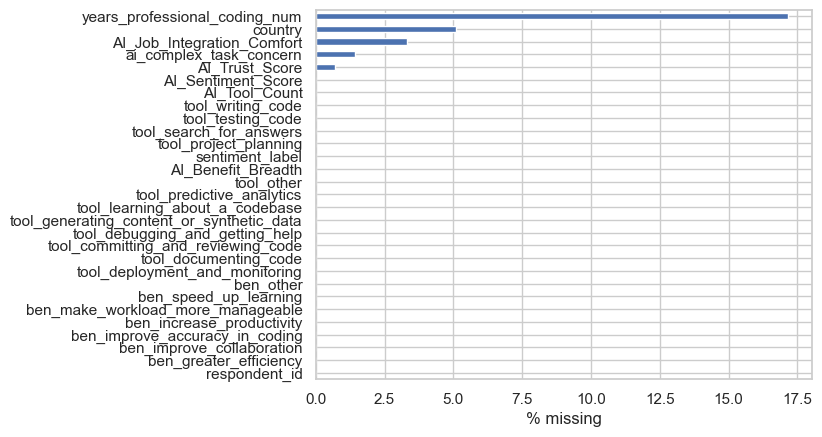

In [24]:
manip = pd.read_csv(P / "02_manipulated.csv")
(manip["AI_Sentiment_Score"].value_counts(normalize=True).sort_index() * 100).plot.bar(color="#1f7a72")
plt.ylabel("% of developers"); plt.title("Target distribution"); plt.show()
(manip.isna().mean() * 100).sort_values().plot.barh()
plt.xlabel("% missing"); plt.show()

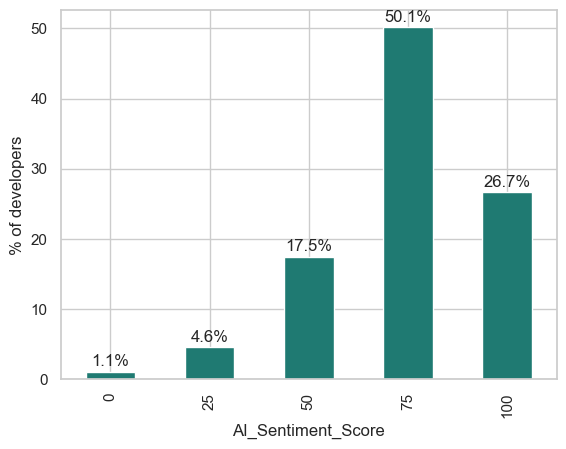

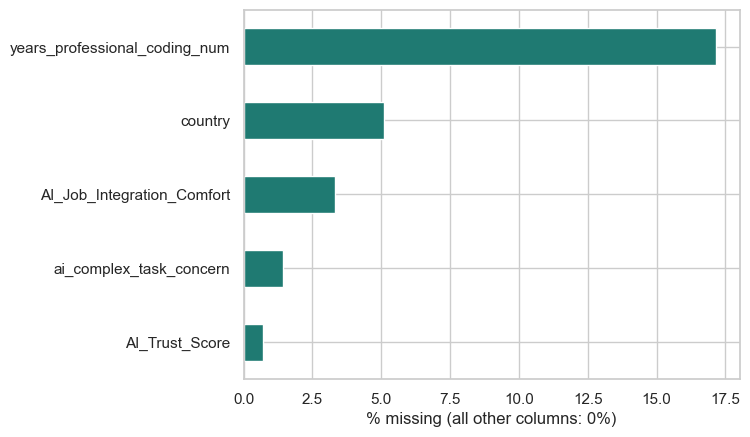

In [25]:
share = manip["AI_Sentiment_Score"].value_counts(normalize=True).sort_index() * 100
share.index = share.index.astype(int)
ax = share.plot.bar(color="#1f7a72")
for i, v in enumerate(share):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_ylabel("% of developers"); plt.show()

cand_cols = [c for c in manip.columns if c not in ("respondent_id", "sentiment_label")]
miss = manip[cand_cols].isna().mean() * 100
miss = miss[miss > 0].sort_values()
miss.plot.barh(color="#1f7a72"); plt.xlabel("% missing (all other columns: 0%)"); plt.show()

AI_Trust_Score                                                  0.460
ai_complex_task_concern                                         0.390
AI_Benefit_Breadth                                              0.367
ben_increase_productivity                                       0.296
AI_Tool_Count                                                   0.291
ben_greater_efficiency                                          0.249
tool_writing_code                                               0.227
ben_improve_accuracy_in_coding                                  0.175
ben_speed_up_learning                                           0.171
tool_debugging_and_getting_help                                 0.169
ben_make_workload_more_manageable                               0.169
tool_learning_about_a_codebase                                  0.155
tool_documenting_code                                           0.149
tool_testing_code                                               0.147
tool_generating_cont

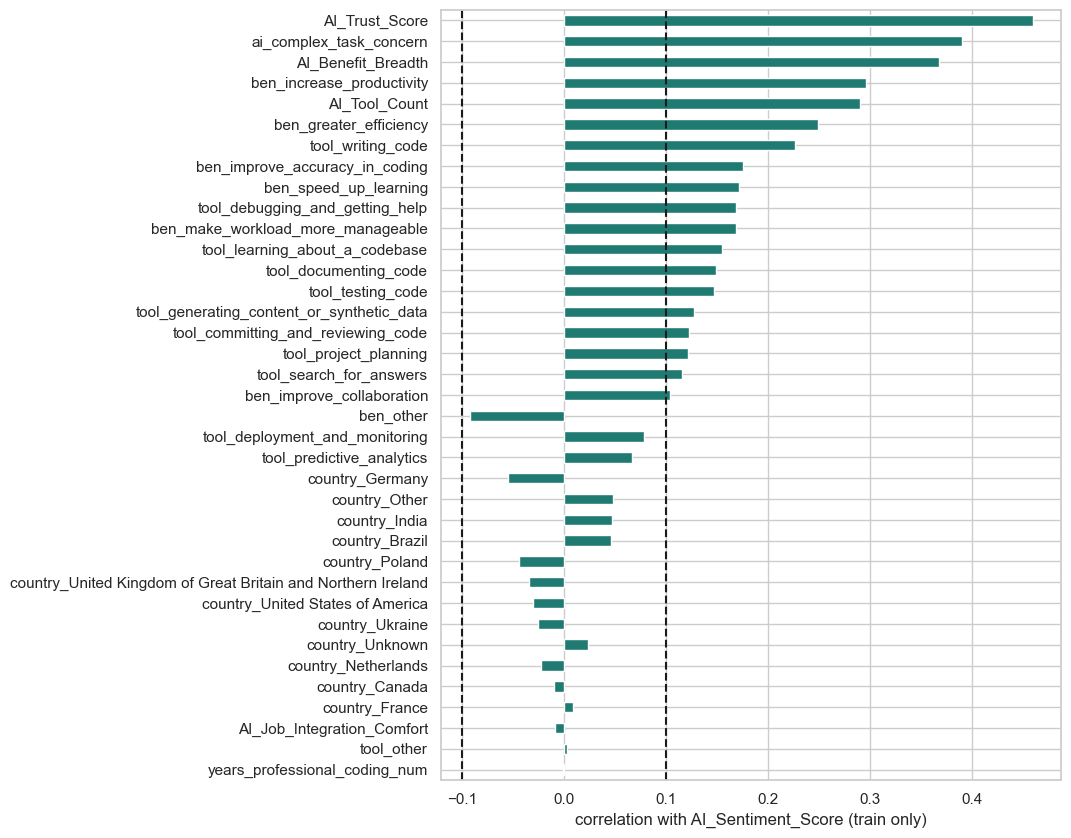

In [26]:
r = X_train.corrwith(y_train)
order = r.abs().sort_values(ascending=False).index
print(r.loc[order].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 10))
r.loc[order[::-1]].plot.barh(ax=ax, color="#1f7a72")
ax.axvline(0.10, ls="--", color="k"); ax.axvline(-0.10, ls="--", color="k")
ax.set_xlabel("correlation with AI_Sentiment_Score (train only)")
fig.savefig("figures/fig_corr_with_target.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
from sklearn.linear_model import LinearRegression
country_cols = [c for c in X_train.columns if c.startswith("country_")]
m = LinearRegression().fit(X_train[country_cols], y_train)
print("country as a group, R2 =", round(m.score(X_train[country_cols], y_train), 3))
print((r**2).sort_values(ascending=False).head(6).round(3))

country as a group, R2 = 0.014
AI_Trust_Score               0.211
ai_complex_task_concern      0.152
AI_Benefit_Breadth           0.135
ben_increase_productivity    0.088
AI_Tool_Count                0.084
ben_greater_efficiency       0.062
dtype: float64


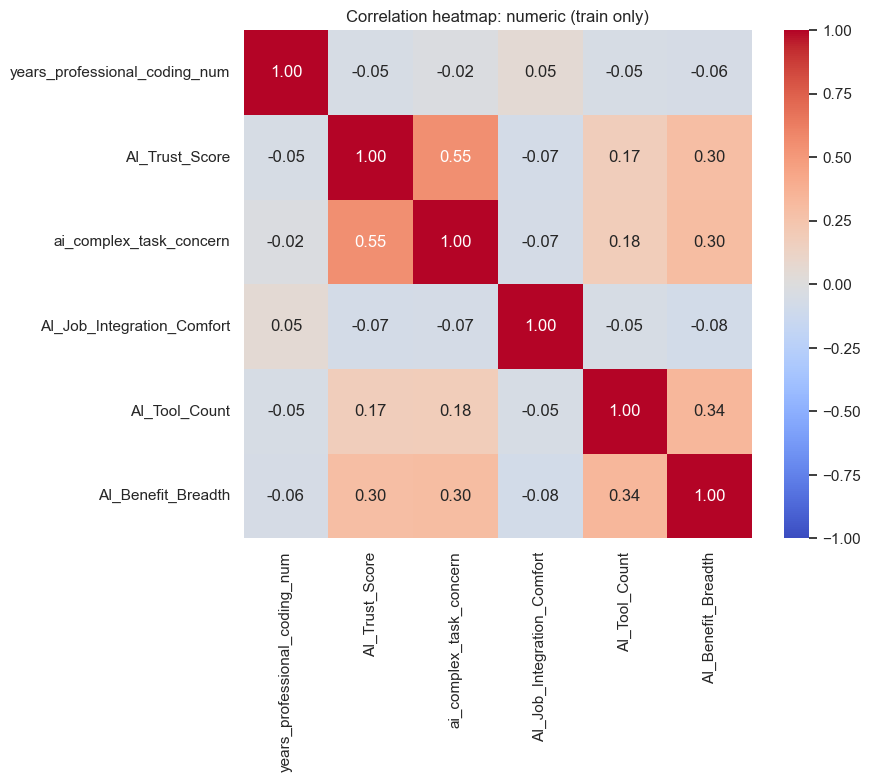

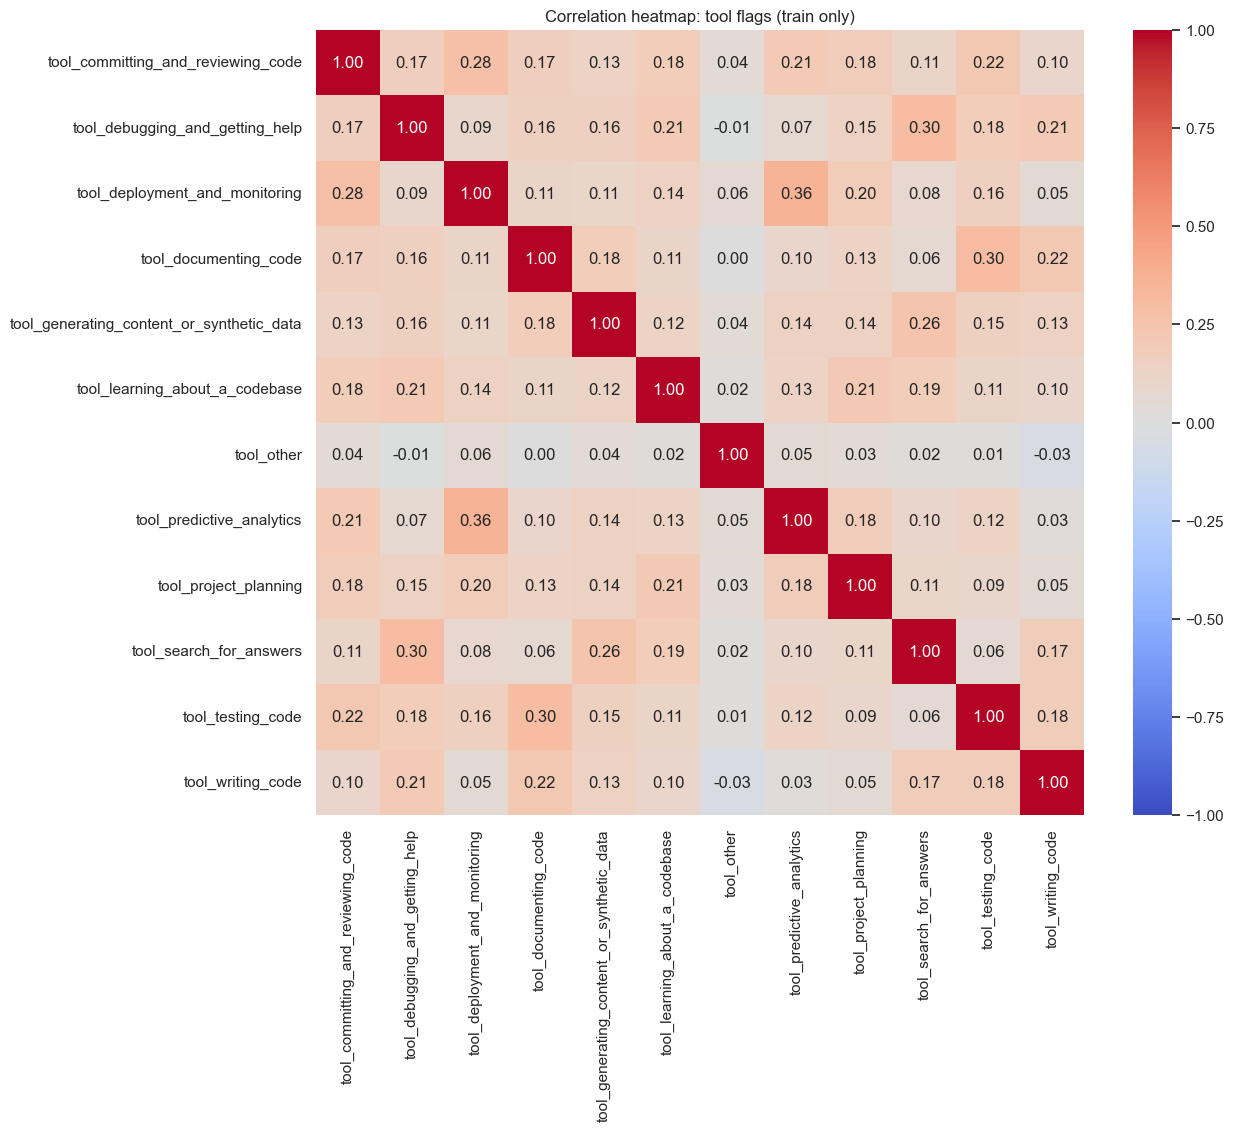

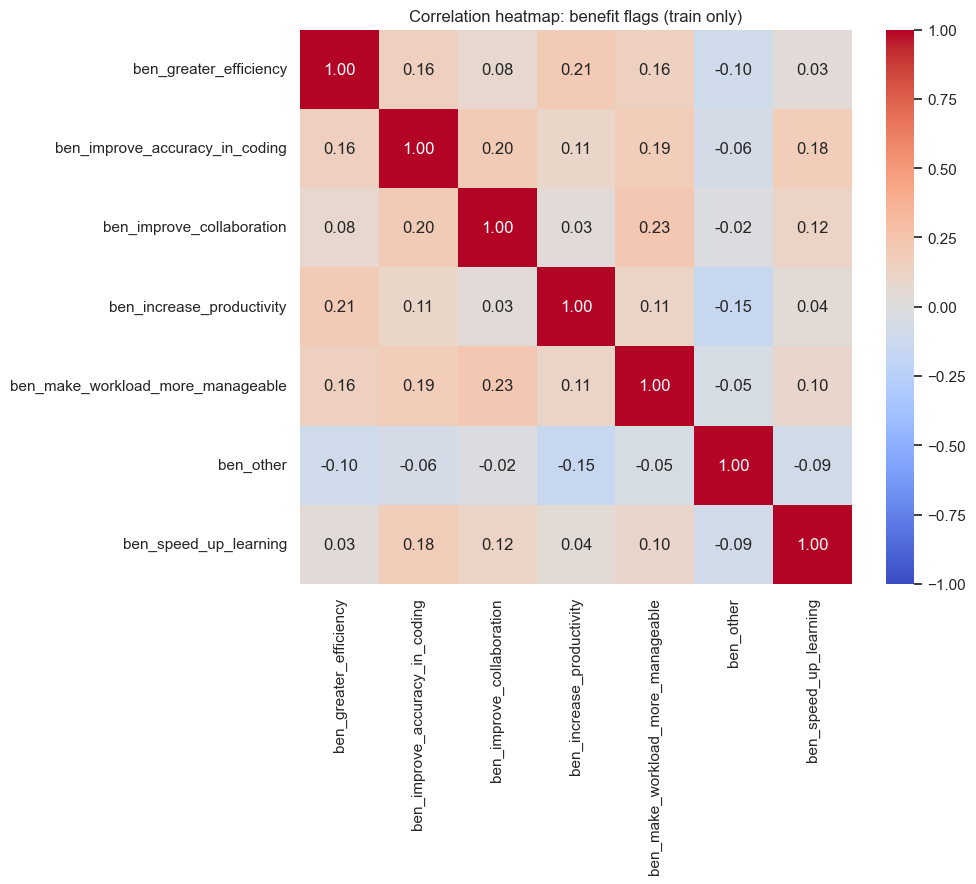

In [28]:
blocks = {
  "numeric": [c for c in X_train.columns if not c.startswith(("tool_", "ben_", "country_"))],
  "tool flags": [c for c in X_train.columns if c.startswith("tool_")],
  "benefit flags": [c for c in X_train.columns if c.startswith("ben_")],
}
for name, cols in blocks.items():
    plt.figure(figsize=(0.7 * len(cols) + 4, 0.6 * len(cols) + 3))
    sns.heatmap(X_train[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(f"Correlation heatmap: {name} (train only)")
    plt.savefig(f"figures/fig_heatmap_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [29]:
corr = X_train.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().reset_index()
pairs.columns = ["a", "b", "r"]
high = pairs[pairs["r"].abs() >= 0.80].sort_values("r", key=abs, ascending=False)
high

,a,b,r


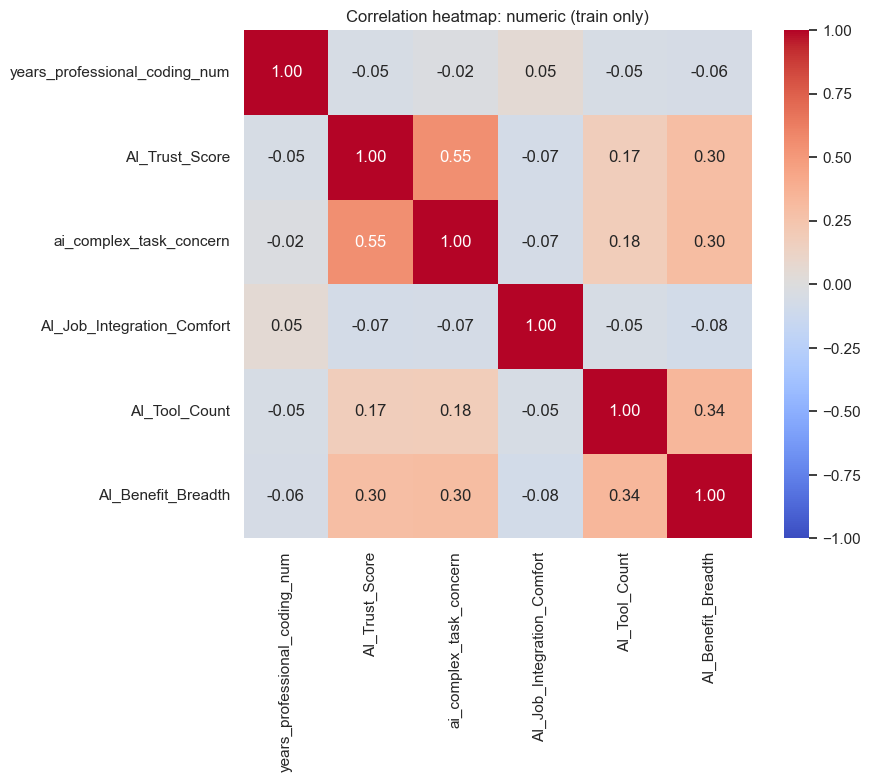

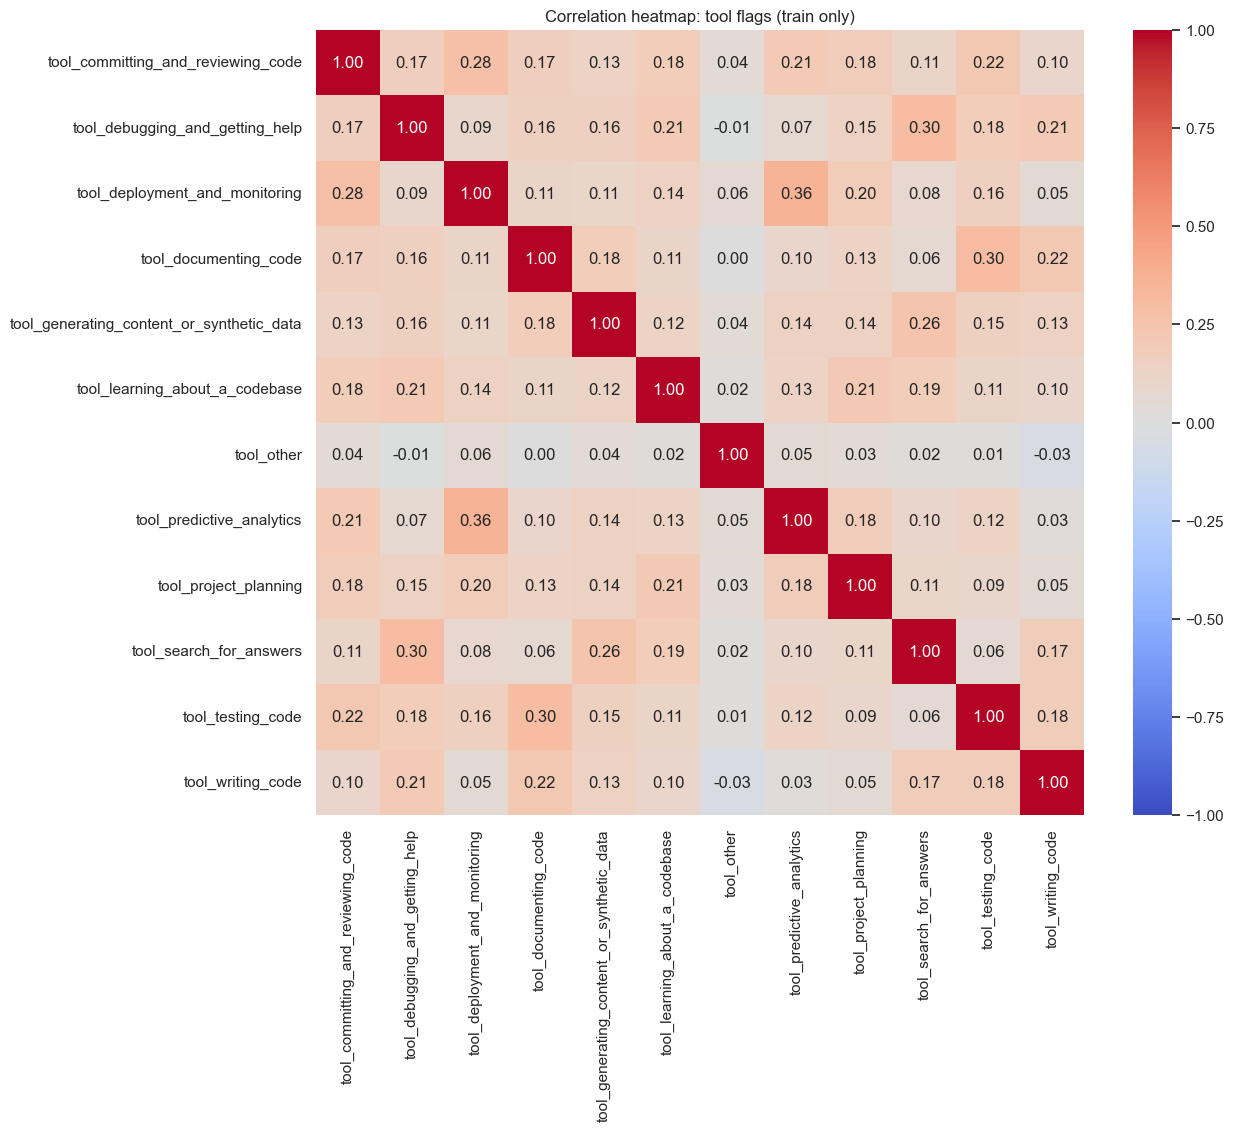

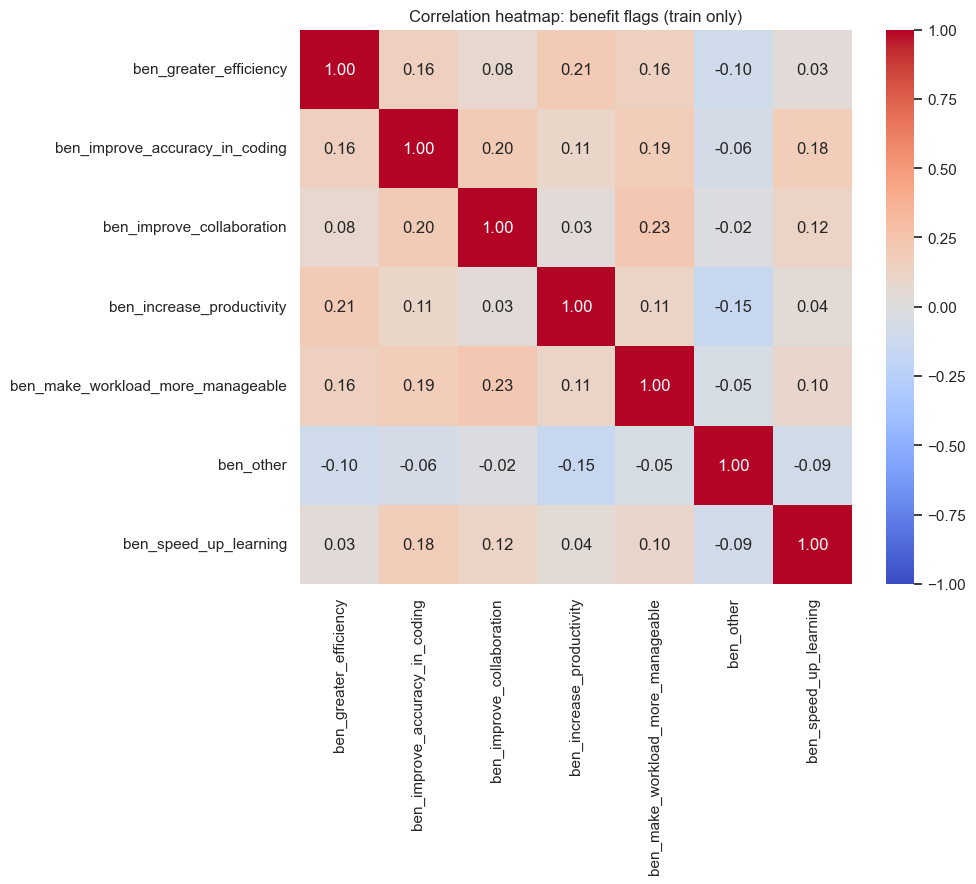

In [30]:
blocks = {
  "numeric": [c for c in X_train.columns if not c.startswith(("tool_", "ben_", "country_"))],
  "tool flags": [c for c in X_train.columns if c.startswith("tool_")],
  "benefit flags": [c for c in X_train.columns if c.startswith("ben_")],
}
for name, cols in blocks.items():
    plt.figure(figsize=(0.7 * len(cols) + 4, 0.6 * len(cols) + 3))
    sns.heatmap(X_train[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title(f"Correlation heatmap: {name} (train only)")
    plt.savefig(f"figures/fig_heatmap_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [31]:
for count_col, prefix in [("AI_Tool_Count", "tool_"), ("AI_Benefit_Breadth", "ben_")]:
    flags = [c for c in X_train.columns if c.startswith(prefix)]
    print(count_col)
    print(X_train[flags].corrwith(X_train[count_col]).round(2).sort_values(ascending=False).to_string(), "\n")

AI_Tool_Count
tool_debugging_and_getting_help              0.57
tool_documenting_code                        0.52
tool_search_for_answers                      0.51
tool_generating_content_or_synthetic_data    0.51
tool_testing_code                            0.50
tool_learning_about_a_codebase               0.49
tool_committing_and_reviewing_code           0.47
tool_writing_code                            0.45
tool_project_planning                        0.41
tool_deployment_and_monitoring               0.37
tool_predictive_analytics                    0.35
tool_other                                   0.09 

AI_Benefit_Breadth
ben_improve_accuracy_in_coding       0.59
ben_greater_efficiency               0.56
ben_make_workload_more_manageable    0.56
ben_speed_up_learning                0.50
ben_increase_productivity            0.45
ben_improve_collaboration            0.43
ben_other                            0.00 



<Axes: >

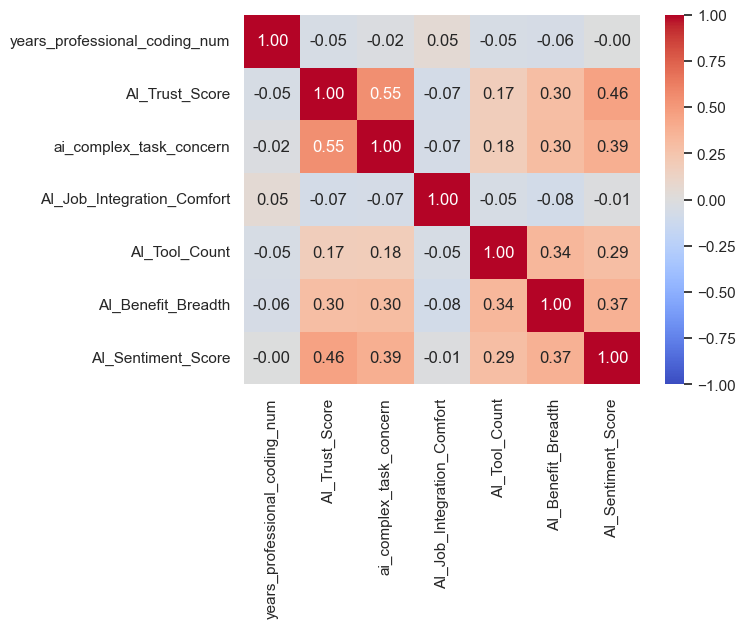

In [32]:
num_cols = blocks["numeric"]
sns.heatmap(X_train[num_cols].assign(AI_Sentiment_Score=y_train).corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

In [33]:
tmp = pd.DataFrame({
    "job_comfort": train_readable["AI_Job_Integration_Comfort"].values,
    "years": train_readable["years_professional_coding_num"].values,
    "sentiment": y_train.values,
})
print(tmp.groupby("job_comfort")["sentiment"].agg(["mean", "count"]).round(1))
print(tmp.groupby(pd.cut(tmp["years"], [-1, 1, 3, 5, 8, 12, 20, 60]), observed=True)["sentiment"].mean().round(1))

             mean  count
job_comfort             
10.0         75.0   3526
50.0         73.9   5692
100.0        74.1  19830
years
(-1, 1]     74.4
(1, 3]      73.8
(3, 5]      74.8
(5, 8]      73.6
(8, 12]     74.3
(12, 20]    73.9
(20, 60]    74.0
Name: sentiment, dtype: float64


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

core = ["AI_Trust_Score", "ai_complex_task_concern"]
set_counts = core + ["AI_Benefit_Breadth", "AI_Tool_Count"]
flags_pass = [c for c in X_train.columns if c.startswith(("ben_", "tool_")) and abs(r[c]) >= 0.10]
set_flags = core + flags_pass

for name, cols in [("counts", set_counts), ("flags", set_flags)]:
    s = cross_val_score(LinearRegression(), X_train[cols], y_train, cv=5, scoring="r2").mean()
    print(name, len(cols), "columns, 5-fold R2 on train =", round(s, 3))

counts 4 columns, 5-fold R2 on train = 0.305
flags 17 columns, 5-fold R2 on train = 0.334


In [35]:
final_x = core + flags_pass + country_cols
reason = {}
for c in X_train.columns:
    if c in final_x:
        continue
    if c in ("AI_Tool_Count", "AI_Benefit_Breadth"):
        reason[c] = "count replaced by its own flags (flags set scored higher in 5-fold CV on train: 0.334 vs 0.305)"
    else:
        reason[c] = f"|r| with y = {abs(r[c]):.3f}, below the 0.10 cut"

Path("feature_selection").mkdir(exist_ok=True)
pd.DataFrame({"selected_feature": final_x}).to_csv("feature_selection/selected_features.csv", index=False)
pd.DataFrame({"dropped": list(reason), "why": list(reason.values())}).to_csv("feature_selection/dropped_features.csv", index=False)
print(len(final_x), "selected;", len(reason), "dropped")

29 selected; 8 dropped
